# 📊 Trabajo Práctico \- Análisis Exploratorio de Datos \(EDA\)

## Materia: Desarrollo de Sistemas de Inteligencia Artificial

## Grupo N° 1

### Integrantes del grupo:

Jorge A. Mendoza \- Dataset: Bank Marketing (bank-additional)
Constanza Soler \- Dataset: Superficie de viñedos 2025 (inv-superficie-viniedos-2025)
Catalina Frione \- Dataset: Adolescentes y videojuegos, Andalucía 2023 (adolescentes_andalucia_2023)
Franco Alfredo Díaz \- Dataset: Estimaciones agrícolas (estimaciones-agricolas-2026-03)
Federico Suárez \- Dataset: Exoplanetas 2021 (all_exoplanets_2021)

# PRIMERA ENTREGA

## 👉🏻 Consigna

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

## 🔍 Introducción

En esta primera entrega cada integrante presenta un análisis exploratorio (EDA) de su propio dataset: banca, vitivinicultura, videojuegos en adolescentes, agricultura y exoplanetas. En cada caso revisamos la estructura de los datos, su calidad y dos visualizaciones clave. Al final comparamos los datasets y elegimos uno para seguir con el proyecto.

# 📁 Dataset 1 – Bank Marketing \(Integrante: Jorge A. Mendoza\)

## 📝 Descripción del Dataset

El dataset contiene información de campañas de marketing telefónico de un banco portugués. Cada fila es un cliente contactado, con datos personales (edad, trabajo, estado civil), datos del contacto (mes, duración, cantidad de llamadas) e indicadores económicos. La variable objetivo "y" indica si el cliente contrató o no un depósito a plazo.

## Importación de Librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1\. Carga y exploración de datos

### Carga del dataset y estructura general

Se carga el archivo (separado por ";") y se revisan dimensiones, tipos de datos y primeras filas.

In [2]:
df_bank = pd.read_csv("bank-additional.csv", sep=";")
print("Dimensiones:", df_bank.shape)
df_bank.info()
df_bank.head()

Dimensiones: (4119, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   object 
 2   marital         4119 non-null   object 
 3   education       4119 non-null   object 
 4   default         4119 non-null   object 
 5   housing         4119 non-null   object 
 6   loan            4119 non-null   object 
 7   contact         4119 non-null   object 
 8   month           4119 non-null   object 
 9   day_of_week     4119 non-null   object 
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   object 
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


El dataset tiene **4119 filas y 21 columnas**: 10 numéricas y 11 categóricas. Cumple con los requisitos mínimos.

### Valores faltantes y valores "unknown"

Se verifica la presencia de nulos. Como las categóricas usan la etiqueta "unknown" en lugar de nulo, también se cuentan esos casos.

In [3]:
print("Nulos totales:", df_bank.isnull().sum().sum())
print("Filas duplicadas:", df_bank.duplicated().sum())
print("\nCantidad de 'unknown' por columna:")
print((df_bank == "unknown").sum()[lambda s: s > 0])

Nulos totales: 0
Filas duplicadas: 0

Cantidad de 'unknown' por columna:
job           39
marital       11
education    167
default      803
housing      105
loan         105
dtype: int64


No hay nulos ni duplicados, pero sí hay valores "unknown". La columna "default" es la más afectada (803 casos, ~20%).

## 2\. Visualizaciones y análisis

### Distribución de la variable objetivo \(y\)

Se grafica cuántos clientes aceptaron el depósito y cuántos no.

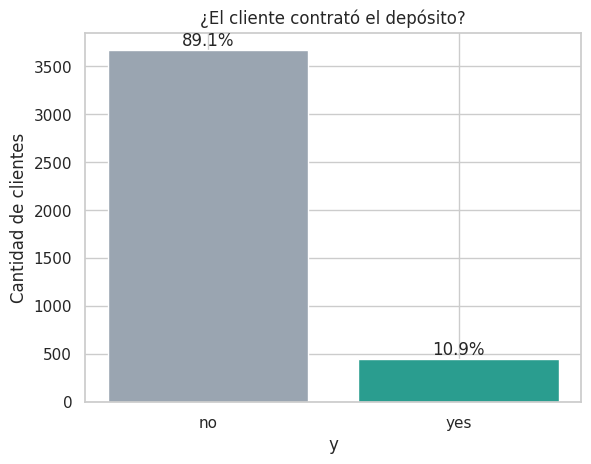

In [4]:
conteo = df_bank["y"].value_counts()

plt.bar(conteo.index, conteo.values, color=["#9aa5b1", "#2a9d8f"])
for i, v in enumerate(conteo.values):
    plt.text(i, v, f"{v / len(df_bank):.1%}", ha="center", va="bottom")
plt.title("¿El cliente contrató el depósito?")
plt.xlabel("y")
plt.ylabel("Cantidad de clientes")
plt.show()

📌 Solo el **11%** de los clientes contrató el depósito. La clase objetivo está muy desbalanceada, y eso habrá que tenerlo en cuenta si se entrena un modelo de clasificación.

### Duración de la llamada según resultado

Se compara la duración de la última llamada (en segundos) entre quienes aceptaron y quienes no.

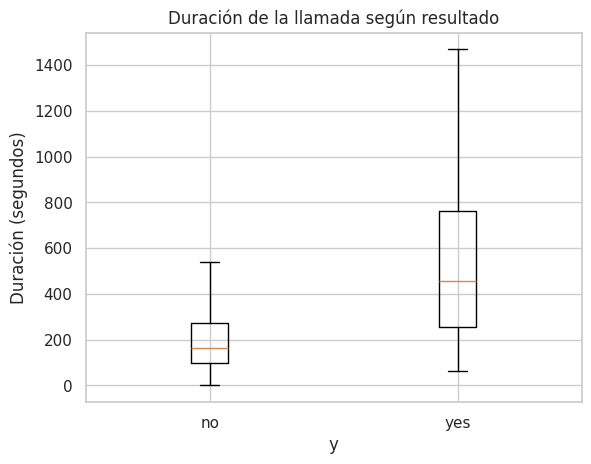

In [5]:
grupos = [df_bank[df_bank["y"] == "no"]["duration"], df_bank[df_bank["y"] == "yes"]["duration"]]

plt.boxplot(grupos, showfliers=False)
plt.xticks([1, 2], ["no", "yes"])
plt.title("Duración de la llamada según resultado")
plt.xlabel("y")
plt.ylabel("Duración (segundos)")
plt.show()

📌 Las llamadas que terminan en "sí" son bastante más largas (mediana de ~458 s contra ~165 s). Sin embargo, la duración se conoce recién al terminar la llamada, así que no serviría para predecir antes del contacto.

## 3\. Observaciones generales

- Datos limpios en cuanto a nulos, aunque con varios "unknown" en variables categóricas.
- Variable objetivo muy desbalanceada (89% / 11%).
- Las variables más interesantes son "duration", "poutcome" (resultado de campañas anteriores) y los indicadores económicos.

# 📁 Dataset 2 – Superficie de viñedos 2025 \(Integrante: Constanza Soler\)

## 📝 Descripción del Dataset

Registro del Instituto Nacional de Vitivinicultura (INV) con la superficie cultivada con vid en Argentina en 2025. Cada fila indica una parcela por provincia, departamento y localidad, con la variedad de uva, su color, el año de plantación, el sistema de conducción y la superficie plantada en hectáreas.

## Importación de Librerías

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

## 1\. Carga y exploración de datos

### Lectura del archivo

Leemos el CSV y miramos cuántas filas y columnas tiene, junto con una muestra de los datos.

In [7]:
vinedos = pd.read_csv("inv-superficie-viniedos-2025.csv")
print(vinedos.shape)
vinedos.sample(5, random_state=1)

(85740, 16)


,anio,provincia,provincia_id,departamento,departamento_id,localidad,localidad_id,variedad,color,anio_plantacion,estado_variedad,tipo_uva,sistema_conduccion,tipo_pie,pie,superficie_plantada
38274,2025,Mendoza,50,San Martín,50098,Alto Verde,50098020,Criolla Grande,rosada,1960,productiva,común,parral,franco,si,1.7000
19628,2025,Mendoza,50,Lavalle,50056,Ingeniero Gustavo André,50056110,Torrontes Riojano,blanca,2012,productiva,fina,espaldera alta,franco,si,2.0000
78105,2025,San Juan,70,San Martín,70091,Dos Acequias,70091020,Cereza,rosada,1993,productiva,común,parral,franco,si,1.8948
18452,2025,Mendoza,50,Lavalle,50056,Costa de Araujo,50056080,Pedro Gimenez,blanca,1961,productiva,fina,parral,franco,si,1.1550
10115,2025,Mendoza,50,Junín,50035,Junín,50035020,Moscatel Rosado,rosada,1982,productiva,común,parral,franco,si,0.7910


Tenemos **85.740 registros y 16 columnas**. La mayoría son categóricas (ubicación, variedad, tipo de uva) y la variable numérica principal es "superficie_plantada".

### Tipos de datos, nulos y resumen numérico

Revisamos los tipos de dato, si hay nulos y las estadísticas básicas de las columnas numéricas.

In [8]:
vinedos.info()
print("\nNulos por columna:", vinedos.isna().sum().sum())
vinedos[["anio_plantacion", "superficie_plantada"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85740 entries, 0 to 85739
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   anio                 85740 non-null  int64  
 1   provincia            85740 non-null  object 
 2   provincia_id         85740 non-null  int64  
 3   departamento         85740 non-null  object 
 4   departamento_id      85740 non-null  int64  
 5   localidad            85740 non-null  object 
 6   localidad_id         85740 non-null  object 
 7   variedad             85740 non-null  object 
 8   color                85740 non-null  object 
 9   anio_plantacion      85740 non-null  int64  
 10  estado_variedad      85740 non-null  object 
 11  tipo_uva             85740 non-null  object 
 12  sistema_conduccion   85740 non-null  object 
 13  tipo_pie             85740 non-null  object 
 14  pie                  85740 non-null  object 
 15  superficie_plantada  85740 non-null 

,anio_plantacion,superficie_plantada
count,85740.000000,85740.000000
mean,1990.671367,2.288548
std,23.058816,3.730277
min,1780.000000,0.000000
25%,1972.000000,0.500000
50%,1999.000000,1.250000
75%,2009.000000,2.636125
max,2025.000000,123.200000


- No hay valores nulos.
- "anio" vale 2025 en todas las filas, así que no aporta información.
- Hay plantaciones registradas desde 1780, y la superficie por registro va de 0 a 123 ha.

## 2\. Visualizaciones y análisis

### Superficie plantada por provincia

Sumamos las hectáreas por provincia para ver dónde se concentra el viñedo argentino.

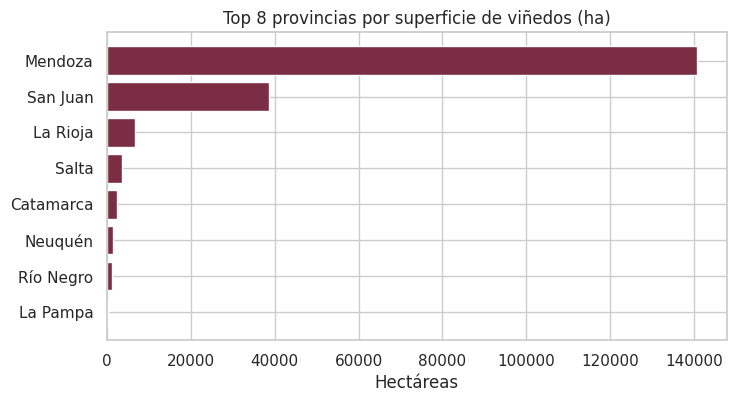

In [9]:
por_prov = vinedos.groupby("provincia")["superficie_plantada"].sum().sort_values().tail(8)

plt.figure(figsize=(8, 4))
plt.barh(por_prov.index, por_prov.values, color="#7b2d43")
plt.title("Top 8 provincias por superficie de viñedos (ha)")
plt.xlabel("Hectáreas")
plt.show()

📌
- **Mendoza** tiene el ~72% de la superficie y **San Juan** otro ~20%.
- Entre las dos suman más del 90% del total. El resto de las provincias tiene muy poca superficie.

### Variedades con más superficie

Vemos cuáles son las 10 variedades de uva con más hectáreas plantadas.

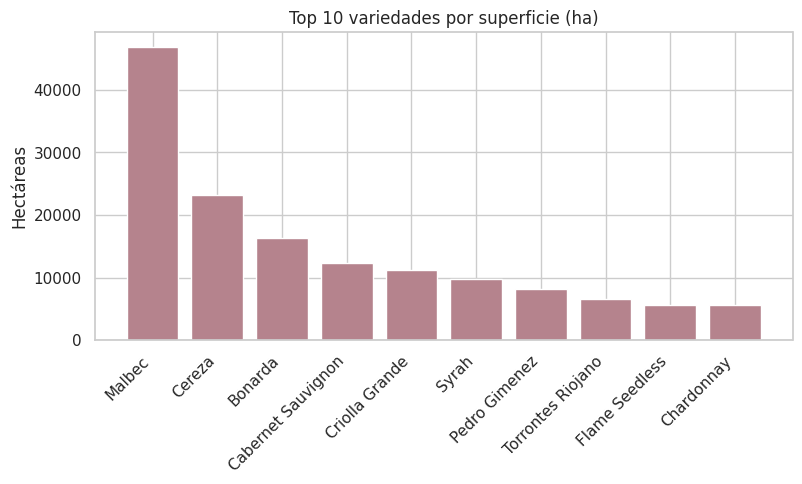

In [10]:
por_var = vinedos.groupby("variedad")["superficie_plantada"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 4))
plt.bar(por_var.index, por_var.values, color="#b5838d")
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 variedades por superficie (ha)")
plt.ylabel("Hectáreas")
plt.show()

📌
- **Malbec** es claramente la principal, con casi el 24% del total.
- Le siguen Cereza y Bonarda, dos uvas asociadas a vinos de mesa o de mayor volumen.

## 3\. Observaciones generales

- Buena calidad de datos: sin nulos y con columnas bien definidas.
- Hay mucha concentración geográfica (Mendoza y San Juan) y varietal (Malbec).
- Las variables más interesantes son "variedad", "color", "anio_plantacion" y "sistema_conduccion". La principal limitación es que el dataset es de un solo año.

# 📁 Dataset 3 – Adolescentes y videojuegos, Andalucía 2023 \(Integrante: Catalina Frione\)

## 📝 Descripción del Dataset

Encuesta a estudiantes de secundaria de Andalucía (España) sobre el uso de videojuegos. Incluye edad, sexo, curso, horas semanales de juego, plataforma y género preferido, puntajes de la escala **GD-20** de trastorno por videojuegos (con sus subescalas) y puntajes de habilidades socioemocionales (SEL).

## Importación de Librerías

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_palette("pastel")

## 1\. Carga y exploración de datos

### Carga y primer vistazo

Cargo el dataset y miro sus dimensiones y las primeras filas.

In [12]:
datos = pd.read_csv("adolescentes_andalucia_2023.csv", encoding="utf-8-sig")
print(f"Filas: {datos.shape[0]} | Columnas: {datos.shape[1]}")
datos.head()

Filas: 3579 | Columnas: 21


,Edad,Sexo,Curso,IES,Provincia,Horas_semana,Plataforma_juego,Género_juego,GD_Prominencia,GD_Animo,...,GD_Abstinencia,GD_Conflicto,GD_Recaida,GD_20,Tipo_jugador,SEL_Autoconciencia,SEL_Concienciasocial,SEL_Autocontrol,SEL_Habilidades,SEL_Decisiones
0,11,1,1,1,4,0.0,1,1,1.0,1.0,...,1.0,1.0,1.0,20,1,3.2,3.4,3.4,4.0,4.0
1,11,1,1,1,4,0.0,1,1,1.0,1.0,...,1.0,1.0,1.0,20,1,3.6,2.4,3.2,3.6,3.2
2,11,1,1,1,4,0.0,1,1,1.0,1.0,...,1.0,1.0,1.0,20,1,2.4,2.4,2.4,3.4,3.6
3,11,1,1,1,4,0.0,4,1,1.0,1.0,...,1.0,1.0,1.0,20,1,4.0,4.0,4.0,4.0,4.0
4,11,1,1,1,4,1.0,2,2,1.0,1.0,...,1.0,1.0,1.0,20,1,3.8,4.0,3.9,4.0,4.0


Son **3579 alumnos y 21 variables**. Todas son numéricas, incluso las categóricas (por ejemplo, "Sexo" vale 1/2 y "Plataforma_juego" va de 1 a 4), así que para interpretarlas hace falta el diccionario de códigos.

### Nulos y estadística descriptiva

Chequeo si hay datos faltantes y cómo se distribuyen las variables principales.

In [13]:
print("Nulos:", datos.isnull().sum().sum())
datos[["Edad", "Horas_semana", "GD_20", "Tipo_jugador"]].describe().round(2)

Nulos: 0


,Edad,Horas_semana,GD_20,Tipo_jugador
count,3579.00,3579.00,3579.00,3579.00
mean,13.46,4.48,31.90,1.20
std,1.34,6.03,10.72,0.53
min,11.00,0.00,20.00,1.00
25%,12.00,1.00,24.00,1.00
50%,13.00,2.00,28.00,1.00
75%,14.00,5.00,38.00,1.00
max,17.00,50.00,82.00,5.00


No hay nulos. La edad va de 11 a 17 años. "Horas_semana" tiene una mediana de 2 h, pero llega a 50 h, lo que sugiere valores extremos. "GD_20" va de 20 a 82.

## 2\. Visualizaciones y análisis

### ¿Cuántas horas por semana juegan?

Hago un histograma de las horas semanales de juego.

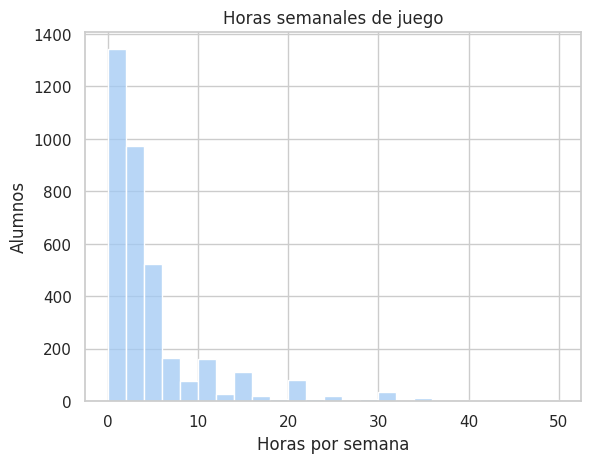

In [14]:
sns.histplot(datos["Horas_semana"], bins=25)
plt.title("Horas semanales de juego")
plt.xlabel("Horas por semana")
plt.ylabel("Alumnos")
plt.show()

📌 La distribución está muy sesgada a la derecha: la mayoría juega pocas horas, pero hay un grupo (~9%) que juega 14 h o más por semana.

### Horas de juego vs. puntaje GD-20

Quiero ver si los que juegan más horas también tienen un puntaje más alto de trastorno por videojuegos.

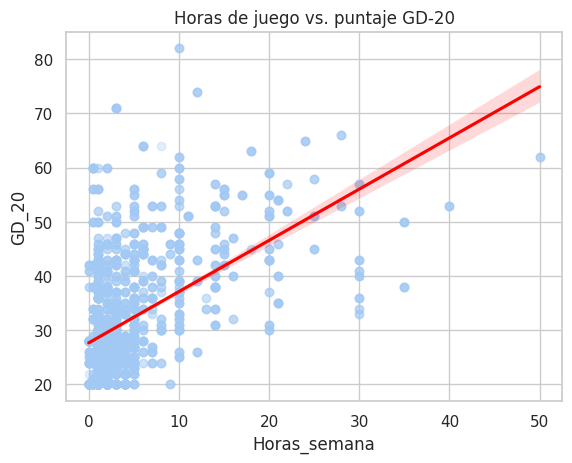

Correlación: 0.53


In [15]:
sns.regplot(data=datos, x="Horas_semana", y="GD_20",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Horas de juego vs. puntaje GD-20")
plt.show()

print("Correlación:", round(datos["Horas_semana"].corr(datos["GD_20"]), 2))

📌 Se ve una relación positiva moderada (**r ≈ 0.53**): a más horas de juego, mayor puntaje GD-20. Igual, hay bastante dispersión.

## 3\. Observaciones generales

El dataset está completo (sin nulos), pero todo viene codificado en números. Lo que más me llamó la atención es la relación entre las horas de juego y el puntaje GD-20, y que la mayoría de los alumnos son "Tipo_jugador" 1 (86%), lo que deja muy pocos casos en los grupos de riesgo. Las variables más interesantes son "Horas_semana", "GD_20" y los puntajes SEL.

# 📁 Dataset 4 – Estimaciones agrícolas \(Integrante: Franco Alfredo Díaz\)

## 📝 Descripción del Dataset

Estimaciones oficiales de la Secretaría de Agricultura de Argentina por cultivo, campaña, provincia y departamento, desde 1969 hasta 2024: superficie sembrada, superficie cosechada, producción (t) y rendimiento (kg/ha). Incluye 41 cultivos.

## Importación de Librerías

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

## 1\. Carga y exploración de datos

### Carga

Carga del CSV y estructura.

In [17]:
agro = pd.read_csv("estimaciones-agricolas-2026-03.csv")
print(agro.shape)
print(agro.dtypes)
agro.head(3)

(160499, 11)
cultivo                     object
anio                         int64
campania                    object
provincia                   object
provincia_id               float64
departamento                object
departamento_id            float64
superficie_sembrada_ha       int64
superficie_cosechada_ha      int64
produccion_tm                int64
rendimiento_kgxha            int64
dtype: object


,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
0,ajo,1969,1969/1970,Buenos Aires,6.0,25 de Mayo,6854.0,3,3,10,3333
1,ajo,1969,1969/1970,Buenos Aires,6.0,Adolfo Gonzales Chaves,6014.0,15,15,82,5467
2,ajo,1969,1969/1970,Buenos Aires,6.0,Almirante Brown,6028.0,2,2,8,4000


160.499 filas x 11 columnas. 4 variables de texto (cultivo, campaña, provincia, departamento) y 7 numéricas (incluye los códigos de provincia/departamento).

### Calidad de datos

Nulos, ceros y cultivos repetidos.

In [18]:
print("Nulos:\n", agro.isna().sum()[agro.isna().sum() > 0])
print("\n% filas con rendimiento = 0:", round((agro["rendimiento_kgxha"] == 0).mean() * 100, 1))
print("\nCultivos:", sorted(agro["cultivo"].unique()))

Nulos:
 provincia          8
provincia_id       8
departamento       8
departamento_id    8
dtype: int64

% filas con rendimiento = 0: 10.4

Cultivos: ['ajo', 'algodón', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'caña de azúcar', 'cebada cervecera', 'cebada forrajera', 'cebada total', 'cebolla total', 'centeno', 'colza', 'cártamo', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limón', 'lino', 'mandarina', 'maní', 'maíz', 'mijo', 'naranja', 'papa total', 'pomelo', 'poroto alubia', 'poroto negro', 'poroto otros', 'poroto total', 'soja 1ra', 'soja 2da', 'soja total', 'sorgo', 'trigo candeal', 'trigo total', 'tung', 'té', 'yerba mate']


- Solo 8 nulos, todos en provincia y departamento.
- ~10% de las filas tiene rendimiento 0 (cosechas perdidas o sin dato).
- Hay categorías "total" que suman subcategorías (p. ej. "soja total" = "soja 1ra" + "soja 2da"). Si se suma todo junto, se cuentan dos veces.

## 2\. Visualizaciones y análisis

### Evolución de la producción: soja, maíz y trigo

Producción nacional por año de los 3 cultivos principales.

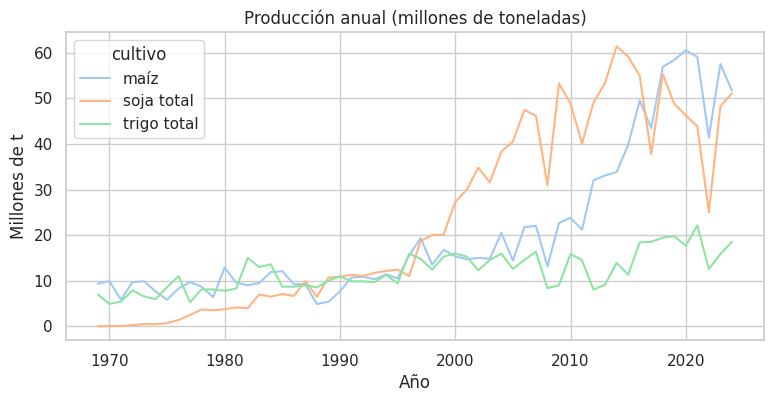

In [19]:
principales = agro[agro["cultivo"].isin(["soja total", "maíz", "trigo total"])]
prod = principales.pivot_table(index="anio", columns="cultivo", values="produccion_tm", aggfunc="sum") / 1e6

prod.plot(figsize=(9, 4), title="Producción anual (millones de toneladas)")
plt.xlabel("Año")
plt.ylabel("Millones de t")
plt.show()

📌
- La soja pasa de casi 0 en 1970 a ~60 Mt en 2015.
- El maíz supera a la soja desde ~2018.
- Caída fuerte en 2022, que coincide con la sequía.

### Provincias productoras de soja

Participación de cada provincia en la producción total de soja (todo el período).

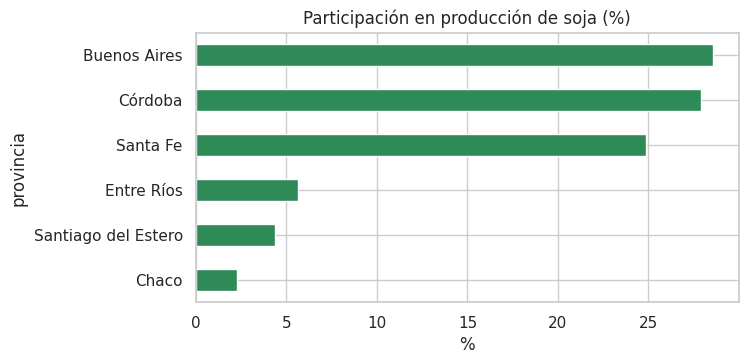

In [20]:
soja = agro[agro["cultivo"] == "soja total"]
part = (soja.groupby("provincia")["produccion_tm"].sum() / soja["produccion_tm"].sum() * 100).sort_values().tail(6)

part.plot(kind="barh", color="seagreen", figsize=(7, 3.5), title="Participación en producción de soja (%)")
plt.xlabel("%")
plt.show()

📌 Buenos Aires, Córdoba y Santa Fe concentran ~81% de la soja. Muy repartido entre las tres.

## 3\. Observaciones generales

- Dataset grande, largo en el tiempo y casi sin nulos.
- Cuidado con los cultivos "total" (doble conteo) y con los rendimientos en 0.
- Variables clave: "produccion_tm", "superficie_sembrada_ha", "rendimiento_kgxha". Sirve para series de tiempo o para predecir rendimiento.

# 📁 Dataset 5 – Exoplanetas 2021 \(Integrante: Federico Suárez\)

## 📝 Descripción del Dataset

Catálogo de exoplanetas confirmados hasta 2021 (basado en el NASA Exoplanet Archive). Cada fila es un planeta, con su método y año de descubrimiento, sus características orbitales (período, semieje mayor, excentricidad), su masa y los datos de su estrella (temperatura, radio, masa, metalicidad, distancia).

## Importación de Librerías

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

## 1\. Carga y exploración de datos

### Cargamos el catálogo

Primero cargamos el CSV y vemos qué columnas trae.

In [22]:
planetas = pd.read_csv("all_exoplanets_2021.csv")
print("Shape:", planetas.shape)
print(list(planetas.columns))
planetas.head()

Shape: (4575, 23)
['No.', 'Planet Name', 'Planet Host', 'Num Stars', 'Num Planets', 'Discovery Method', 'Discovery Year', 'Discovery Facility', 'Orbital Period Days', 'Orbit Semi-Major Axis', 'Mass', 'Eccentricity', 'Insolation Flux', 'Equilibrium Temperature', 'Spectral Type', 'Stellar Effective Temperature', 'Stellar Radius', 'Stellar Mass', 'Stellar Metallicity', 'Stellar Metallicity Ratio', 'Stellar Surface Gravity', 'Distance', 'Gaia Magnitude']


,No.,Planet Name,Planet Host,Num Stars,Num Planets,Discovery Method,Discovery Year,Discovery Facility,Orbital Period Days,Orbit Semi-Major Axis,...,Equilibrium Temperature,Spectral Type,Stellar Effective Temperature,Stellar Radius,Stellar Mass,Stellar Metallicity,Stellar Metallicity Ratio,Stellar Surface Gravity,Distance,Gaia Magnitude
0,1,11 Com b,11 Com,2,1,Radial Velocity,2007,Xinglong Station,326.03000,1.29,...,NaN,G8 III,4742.0,19.00,2.70,-0.35,[Fe/H],2.31,93.1846,4.44038
1,2,11 UMi b,11 UMi,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,516.21997,1.53,...,NaN,NaN,4213.0,29.79,2.78,-0.02,[Fe/H],1.93,125.3210,4.56216
2,3,14 And b,14 And,1,1,Radial Velocity,2008,Okayama Astrophysical Observatory,185.84000,0.83,...,NaN,K0 III,4813.0,11.00,2.20,-0.24,[Fe/H],2.63,75.4392,4.91781
3,4,14 Her b,14 Her,1,2,Radial Velocity,2002,W. M. Keck Observatory,1773.40002,2.93,...,NaN,NaN,5338.0,0.93,0.90,0.41,[Fe/H],4.45,17.9323,6.38300
4,5,16 Cyg B b,16 Cyg B,3,1,Radial Velocity,1996,Multiple Observatories,798.50000,1.66,...,NaN,NaN,5750.0,1.13,1.08,0.06,[Fe/H],4.36,21.1397,6.06428


Tenemos **4575 planetas y 23 columnas**. La columna "No." es solo un índice. Hay 6 columnas de texto (nombre, estrella, método, observatorio, etc.) y el resto son numéricas.

### ¿Cuántos datos faltan?

En catálogos astronómicos suele faltar mucha información, así que calculamos el % de nulos por columna.

In [23]:
nulos = (planetas.isna().mean() * 100).round(1).sort_values(ascending=False)
nulos[nulos > 0]

Insolation Flux                  91.9
Equilibrium Temperature          79.8
Spectral Type                    79.7
Eccentricity                     62.7
Mass                             56.2
Orbit Semi-Major Axis            39.6
Stellar Metallicity Ratio        30.2
Stellar Metallicity              30.0
Stellar Mass                     16.0
Stellar Surface Gravity          13.2
Stellar Radius                    9.8
Stellar Effective Temperature     7.6
Gaia Magnitude                    3.8
Orbital Period Days               3.5
Distance                          2.3
dtype: float64

Este es el punto débil del dataset: "Insolation Flux" tiene 92% de nulos y "Equilibrium Temperature" 80%. La masa del planeta falta en el 56% de los casos. En cambio, las variables del descubrimiento están completas.

## 2\. Visualizaciones y análisis

### Descubrimientos por año y método

Graficamos cuántos planetas se descubrieron cada año, separando los dos métodos principales del resto.

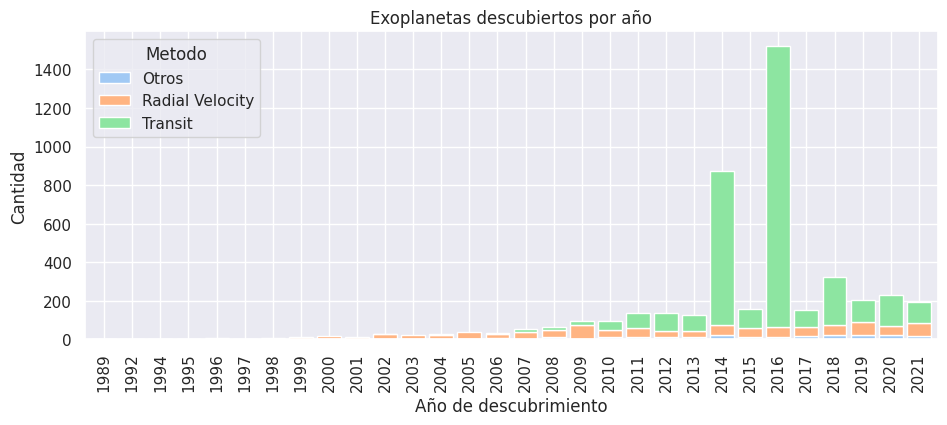

In [24]:
planetas["Metodo"] = planetas["Discovery Method"].where(
    planetas["Discovery Method"].isin(["Transit", "Radial Velocity"]), "Otros")

por_anio = planetas.groupby(["Discovery Year", "Metodo"]).size().unstack(fill_value=0)
por_anio.plot(kind="bar", stacked=True, figsize=(11, 4), width=0.85)
plt.title("Exoplanetas descubiertos por año")
plt.xlabel("Año de descubrimiento")
plt.ylabel("Cantidad")
plt.show()

📌 El método de **tránsito** domina (75% del total) y explica los picos de 2014 y 2016, que corresponden a las publicaciones masivas del telescopio **Kepler**. Antes de 2010, casi todo se descubría por velocidad radial.

### Período orbital vs. masa

Comparamos el período orbital con la masa (en masas terrestres) en escala logarítmica, coloreando según el método de descubrimiento.

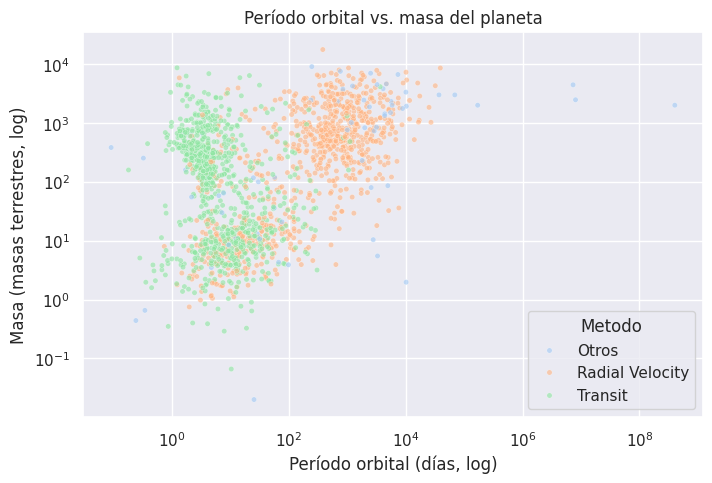

In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=planetas, x="Orbital Period Days", y="Mass", hue="Metodo", hue_order=["Otros", "Radial Velocity", "Transit"], alpha=0.6, s=15)
plt.xscale("log")
plt.yscale("log")
plt.title("Período orbital vs. masa del planeta")
plt.xlabel("Período orbital (días, log)")
plt.ylabel("Masa (masas terrestres, log)")
plt.show()

📌 Cada método "ve" un tipo distinto de planeta: el tránsito encuentra sobre todo planetas de órbita corta (pocos días) y la velocidad radial detecta planetas más masivos, de tipo Júpiter. Se forman grupos bastante claros, algo interesante para hacer clustering.

## 3\. Observaciones generales

Es un dataset muy rico en variables físicas y con un tema atractivo. El gran problema es la cantidad de nulos en varias columnas, que obliga a elegir bien qué variables usar o a imputarlas. Lo más interesante: el sesgo que introduce el método de descubrimiento y la relación entre la masa, el período y las propiedades de la estrella.

# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

## 🏆 Dataset elegido: Exoplanetas 2021 \(all\_exoplanets\_2021\)

## 📌 Motivos de la elección:

- Tiene muchas variables numéricas (orbitales y estelares) y 4575 registros.

- Trata una problemática científica actual y con datos reales (NASA Exoplanet Archive).

- Se ve potencial para aplicar IA: clasificar el método de descubrimiento, predecir la masa del planeta o agrupar tipos de planetas con clustering.

- Los nulos son un desafío, pero también una oportunidad para trabajar la limpieza y la imputación de datos.

## 💡 Próximos pasos

- Limpieza y preparación del dataset elegido\.

- Diseño de una solución basada en la problemática detectada\.

- Implementación y validación del modelo\.

# SEGUNDA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Análisis EDA \(según lo trabajaron en la entrega 1\)
Análisis univariado, bivariado y/o multivariado
4 hipótesis sobre el dataset
Gráficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.

## 🔍 Introducción

# 📁 Dataset seleccionado – all\_exoplanets\_2021\.csv 

## 📝 Descripción del Dataset

Catálogo de exoplanetas confirmados hasta 2021 \(basado en el NASA Exoplanet Archive\)\. Cada fila es un planeta, con su método y año de descubrimiento, sus datos orbitales \(período, semieje mayor, excentricidad\), su masa \(en masas terrestres\) y los datos de su estrella \(temperatura, radio, masa, metalicidad, distancia\)\.

## Importación de Librerías

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1\. Carga y exploración de datos

### Carga del catálogo

Carga del CSV y revisión de dimensiones, tipos de datos y primeras filas\.

In [27]:
planetas = pd.read_csv("all_exoplanets_2021.csv")
print("Shape:", planetas.shape)
planetas.info()
planetas.head()

Shape: (4575, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4575 entries, 0 to 4574
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   No.                            4575 non-null   int64  
 1   Planet Name                    4575 non-null   object 
 2   Planet Host                    4575 non-null   object 
 3   Num Stars                      4575 non-null   int64  
 4   Num Planets                    4575 non-null   int64  
 5   Discovery Method               4575 non-null   object 
 6   Discovery Year                 4575 non-null   int64  
 7   Discovery Facility             4575 non-null   object 
 8   Orbital Period Days            4413 non-null   float64
 9   Orbit Semi-Major Axis          2763 non-null   float64
 10  Mass                           2006 non-null   float64
 11  Eccentricity                   1707 non-null   float64
 12  Insolation Flux               

,No.,Planet Name,Planet Host,Num Stars,Num Planets,Discovery Method,Discovery Year,Discovery Facility,Orbital Period Days,Orbit Semi-Major Axis,...,Equilibrium Temperature,Spectral Type,Stellar Effective Temperature,Stellar Radius,Stellar Mass,Stellar Metallicity,Stellar Metallicity Ratio,Stellar Surface Gravity,Distance,Gaia Magnitude
0,1,11 Com b,11 Com,2,1,Radial Velocity,2007,Xinglong Station,326.03000,1.29,...,NaN,G8 III,4742.0,19.00,2.70,-0.35,[Fe/H],2.31,93.1846,4.44038
1,2,11 UMi b,11 UMi,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,516.21997,1.53,...,NaN,NaN,4213.0,29.79,2.78,-0.02,[Fe/H],1.93,125.3210,4.56216
2,3,14 And b,14 And,1,1,Radial Velocity,2008,Okayama Astrophysical Observatory,185.84000,0.83,...,NaN,K0 III,4813.0,11.00,2.20,-0.24,[Fe/H],2.63,75.4392,4.91781
3,4,14 Her b,14 Her,1,2,Radial Velocity,2002,W. M. Keck Observatory,1773.40002,2.93,...,NaN,NaN,5338.0,0.93,0.90,0.41,[Fe/H],4.45,17.9323,6.38300
4,5,16 Cyg B b,16 Cyg B,3,1,Radial Velocity,1996,Multiple Observatories,798.50000,1.66,...,NaN,NaN,5750.0,1.13,1.08,0.06,[Fe/H],4.36,21.1397,6.06428


Son 4575 planetas y 23 columnas: 6 de texto y 17 numéricas\. Las columnas del descubrimiento \(método, año, observatorio\) están completas\.

### Porcentaje de nulos por columna

Cálculo del % de nulos por columna, el punto débil del dataset según la primera entrega\.

In [28]:
nulos = (planetas.isna().mean() * 100).round(1).sort_values(ascending=False)
nulos[nulos > 0]

Insolation Flux                  91.9
Equilibrium Temperature          79.8
Spectral Type                    79.7
Eccentricity                     62.7
Mass                             56.2
Orbit Semi-Major Axis            39.6
Stellar Metallicity Ratio        30.2
Stellar Metallicity              30.0
Stellar Mass                     16.0
Stellar Surface Gravity          13.2
Stellar Radius                    9.8
Stellar Effective Temperature     7.6
Gaia Magnitude                    3.8
Orbital Period Days               3.5
Distance                          2.3
dtype: float64

Hay 3 columnas casi vacías: "Insolation Flux" \(92%\), "Equilibrium Temperature" \(80%\) y "Spectral Type" \(80%\)\. La masa falta en el 56% de los planetas, pero es una variable clave, así que se conserva\.

## 2\. Limpieza de Datos

## Analisis Univariado

### Nulos después de la limpieza

Eliminación de las columnas y gráfico del % de nulos de las que quedan\.

Shape: (4575, 18)


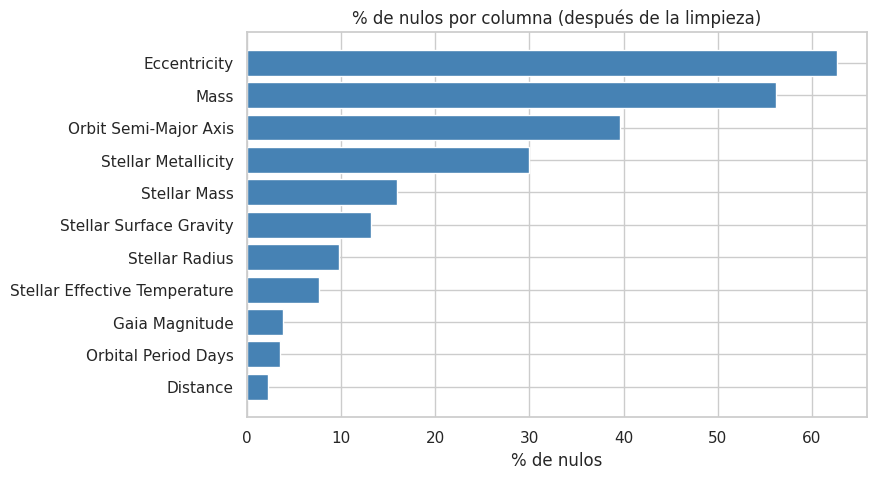

In [29]:
limpio = planetas.drop(columns=["No.", "Insolation Flux", "Equilibrium Temperature",
                                "Spectral Type", "Stellar Metallicity Ratio"])
print("Shape:", limpio.shape)

nulos_limpio = (limpio.isna().mean() * 100).sort_values()
nulos_limpio = nulos_limpio[nulos_limpio > 0]

plt.figure(figsize=(8, 5))
plt.barh(nulos_limpio.index, nulos_limpio.values, color="steelblue")
plt.title("% de nulos por columna (después de la limpieza)")
plt.xlabel("% de nulos")
plt.show()

📌 Quedan 4575 filas y 18 columnas\. La excentricidad \(63%\) y la masa \(56%\) siguen siendo las que más datos pierden\. El resto de las columnas tiene menos del 40% de nulos\.

El dataset queda más liviano y sin columnas inútiles\. Como no se imputa, la cantidad de planetas de cada análisis depende de las columnas que usa\.

## 3\. Visualizaciones y análisis

## Analisis Univariado

### Distribución de la masa de los planetas

Histograma de la masa con el eje en escala logarítmica, porque los valores van de 0,02 a más de 17\.000 masas terrestres\.

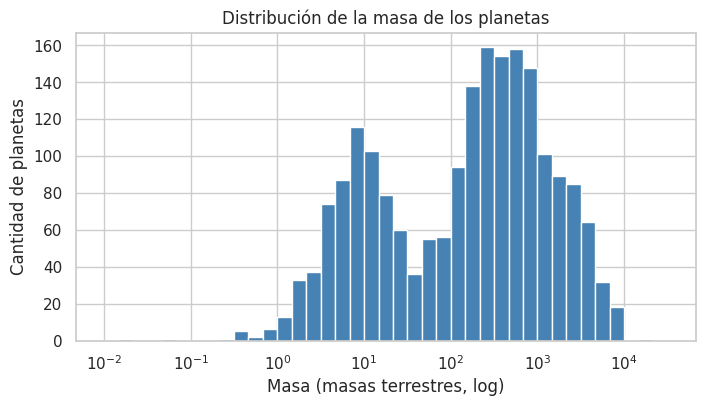

In [30]:
masa = limpio["Mass"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(masa, bins=np.logspace(-2, 4.5, 40), color="steelblue", edgecolor="white")
plt.xscale("log")
plt.title("Distribución de la masa de los planetas")
plt.xlabel("Masa (masas terrestres, log)")
plt.ylabel("Cantidad de planetas")
plt.show()

In [31]:
print(f"Planetas con masa > 100 masas terrestres: {(masa > 100).mean() * 100:.1f}%")

Planetas con masa > 100 masas terrestres: 61.8%


📌 La distribución tiene dos picos: uno cerca de 10 masas terrestres \("súper Tierras" y mini Neptunos\) y otro cerca de 300\-1000 \(gigantes tipo Júpiter\)\. El 62% de los planetas con masa conocida tiene más de 100 masas terrestres\.

Hay dos familias de planetas bien diferenciadas por su masa\. Los gigantes están sobrerrepresentados, algo que tiene sentido porque son los más fáciles de detectar\.

## Analisis Bivariado

### Período orbital vs\. masa

Comparación entre el período orbital \(lo que tarda cada planeta en dar la vuelta a su estrella\) y su masa, las dos en escala logarítmica\.

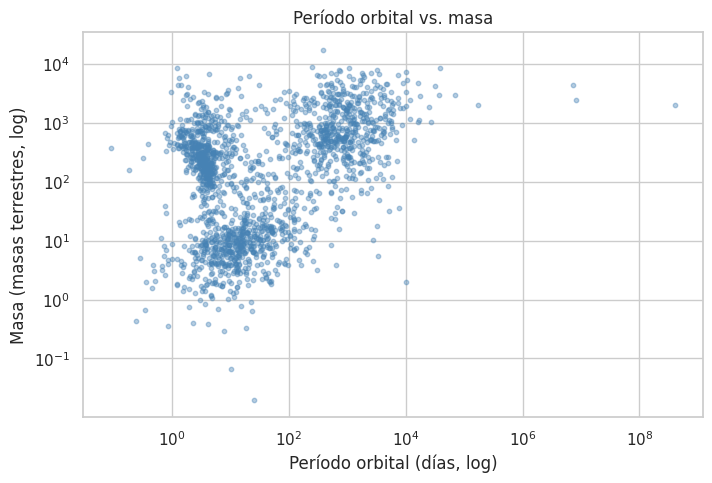

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(limpio["Orbital Period Days"], limpio["Mass"], s=10, alpha=0.4, color="steelblue")
plt.xscale("log")
plt.yscale("log")
plt.title("Período orbital vs. masa")
plt.xlabel("Período orbital (días, log)")
plt.ylabel("Masa (masas terrestres, log)")
plt.show()

📌 Aparecen tres nubes: gigantes muy pegados a su estrella \("Júpiter calientes", con períodos de pocos días\), planetas chicos de órbita corta y gigantes con órbitas largas \(cientos o miles de días\)\.

### Masa según el método de descubrimiento

Comparación de la masa de los planetas para los 4 métodos con más casos\.

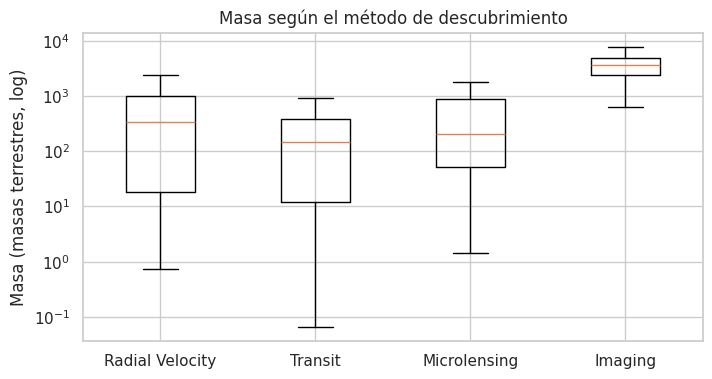

In [33]:
metodos = ["Radial Velocity", "Transit", "Microlensing", "Imaging"]
grupos = [limpio[limpio["Discovery Method"] == m]["Mass"].dropna() for m in metodos]

plt.figure(figsize=(8, 4))
plt.boxplot(grupos, showfliers=False)
plt.xticks([1, 2, 3, 4], metodos)
plt.yscale("log")
plt.title("Masa según el método de descubrimiento")
plt.ylabel("Masa (masas terrestres, log)")
plt.show()

In [34]:
mediana_metodo = limpio[limpio["Discovery Method"].isin(metodos)].groupby("Discovery Method")["Mass"].median()
print(mediana_metodo.round(0))

Discovery Method
Imaging            3575.0
Microlensing        205.0
Radial Velocity     344.0
Transit             145.0
Name: Mass, dtype: float64


📌 La imagen directa solo encuentra planetas enormes \(mediana de ~3500 masas terrestres\)\. La velocidad radial también detecta planetas grandes \(~344\), y el tránsito es el que llega a planetas más chicos\.

### Distancia de los planetas según el año de descubrimiento

Distancia mediana \(en pársecs\) de los planetas descubiertos cada año, desde 1995, porque antes hay solo 4 descubrimientos\.

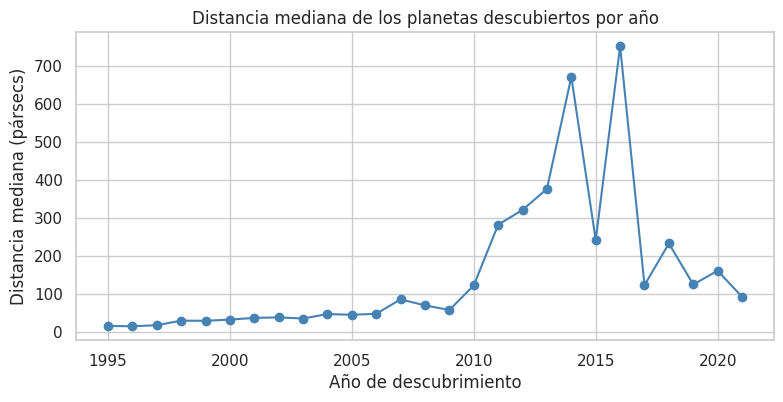

In [35]:
desde_1995 = limpio[limpio["Discovery Year"] >= 1995]
distancia_anio = desde_1995.groupby("Discovery Year")["Distance"].median()

plt.figure(figsize=(9, 4))
plt.plot(distancia_anio.index, distancia_anio.values, marker="o", color="steelblue")
plt.title("Distancia mediana de los planetas descubiertos por año")
plt.xlabel("Año de descubrimiento")
plt.ylabel("Distancia mediana (pársecs)")
plt.show()

In [36]:
print("Descubrimientos antes de 1995:", (limpio["Discovery Year"] < 1995).sum())

Descubrimientos antes de 1995: 4


📌 Hasta 2009 la distancia mediana se mantiene por debajo de 100 pársecs\. Con el telescopio Kepler la distancia sube mucho \(pico de ~750 pársecs en 2016\)\. Después baja otra vez, ya que las misiones más nuevas buscan en estrellas cercanas\.

Cada método y cada misión "ve" planetas distintos: los métodos determinan qué masas y qué distancias aparecen en el catálogo\. Esto hay que tenerlo en cuenta antes de sacar conclusiones físicas\.

## Analisis Multivariado

### Período vs\. masa según el método de descubrimiento

Gráfico de período vs\. masa con cada punto coloreado según el método con el que se descubrió\.

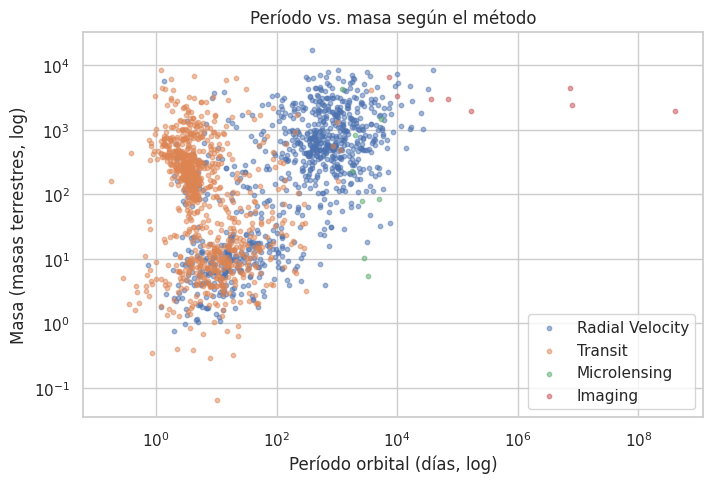

In [37]:
plt.figure(figsize=(8, 5))
for metodo in ["Radial Velocity", "Transit", "Microlensing", "Imaging"]:
    grupo = limpio[limpio["Discovery Method"] == metodo]
    plt.scatter(grupo["Orbital Period Days"], grupo["Mass"], s=10, alpha=0.5, label=metodo)
plt.xscale("log")
plt.yscale("log")
plt.title("Período vs. masa según el método")
plt.xlabel("Período orbital (días, log)")
plt.ylabel("Masa (masas terrestres, log)")
plt.legend()
plt.show()

📌 Las tres nubes del gráfico bivariado son, en parte, un sesgo de detección: el tránsito encuentra planetas de órbita corta, la velocidad radial encuentra gigantes con órbitas largas y la imagen directa encuentra gigantes muy lejos de su estrella\.

### Correlaciones entre variables numéricas

Mapa de calor con la correlación de Spearman, que funciona mejor que la de Pearson con variables tan asimétricas\.

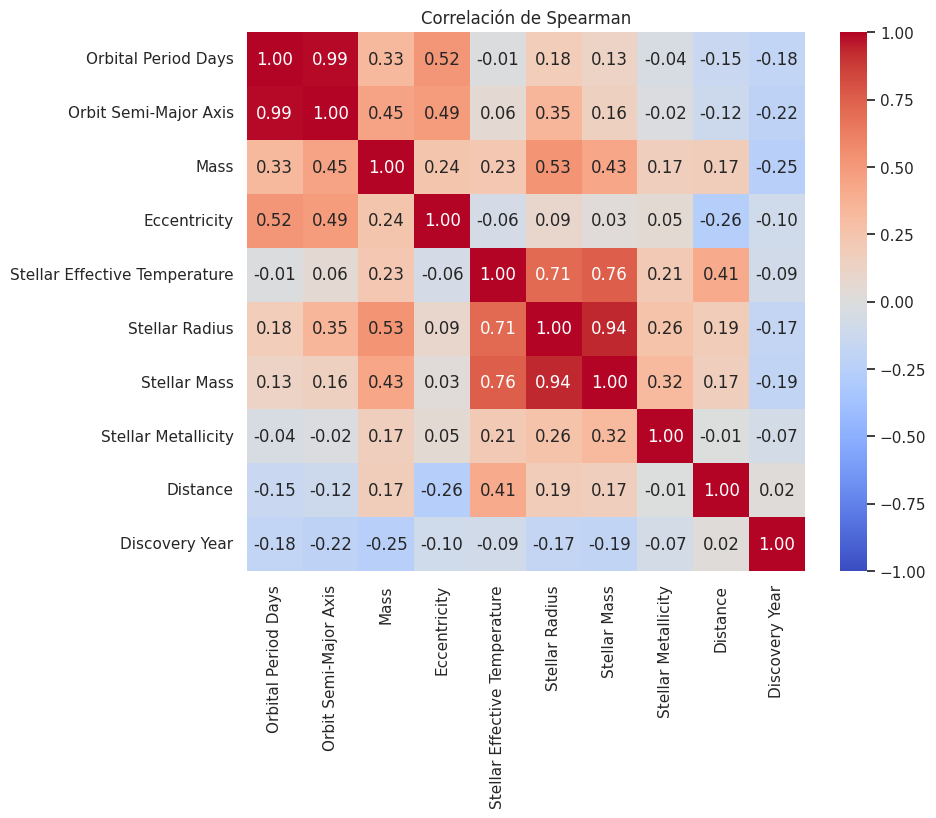

In [38]:
columnas = ["Orbital Period Days", "Orbit Semi-Major Axis", "Mass", "Eccentricity",
            "Stellar Effective Temperature", "Stellar Radius", "Stellar Mass",
            "Stellar Metallicity", "Distance", "Discovery Year"]
correlacion = limpio[columnas].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Spearman")
plt.show()

📌 La relación más fuerte es período vs\. semieje mayor \(0\.99\), que es la ley de Kepler\. También se relacionan mucho el radio, la masa y la temperatura de la estrella \(0\.71 a 0\.94\)\. La masa del planeta se relaciona en forma moderada con el radio de la estrella \(0\.53\) y con la excentricidad \(0\.24\)\.

### Masa vs\. radio de la estrella según su temperatura

Masa contra radio de las estrellas que tienen planetas, con el color según su temperatura\.

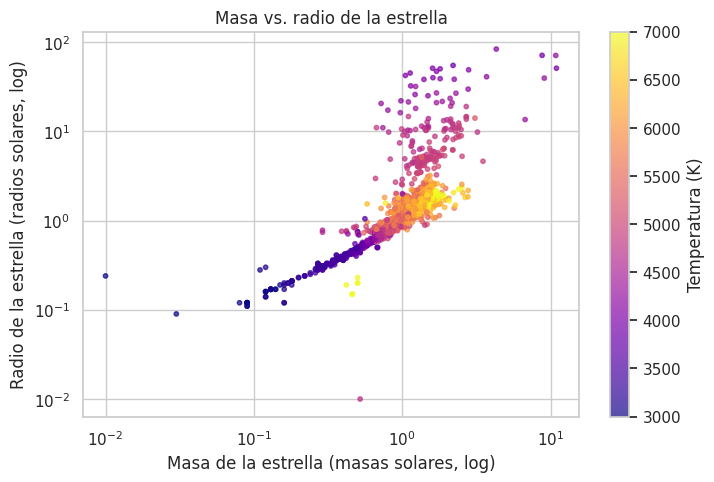

In [39]:
estrellas = limpio.dropna(subset=["Stellar Mass", "Stellar Radius", "Stellar Effective Temperature"])

plt.figure(figsize=(8, 5))
plt.scatter(estrellas["Stellar Mass"], estrellas["Stellar Radius"], c=estrellas["Stellar Effective Temperature"],
            cmap="plasma", s=10, alpha=0.7, vmin=3000, vmax=7000)
plt.colorbar(label="Temperatura (K)")
plt.xscale("log")
plt.yscale("log")
plt.title("Masa vs. radio de la estrella")
plt.xlabel("Masa de la estrella (masas solares, log)")
plt.ylabel("Radio de la estrella (radios solares, log)")
plt.show()

📌 La mayoría de las estrellas forma una línea en la que a más masa hay más radio y más temperatura\. Arriba de esa línea aparece un grupo de estrellas frías con radios muy grandes: son gigantes rojas\.

El método de descubrimiento explica buena parte de lo que aparece en el catálogo\. Las variables de la estrella están muy relacionadas entre sí, lo que sirve para imputar nulos en próximas etapas\.

## 4\. Planteo de Hipótesis

### Hipótesis 1: los planetas descubiertos por tránsito tienen órbitas más cortas que los de velocidad radial

El tránsito necesita ver pasar al planeta delante de su estrella varias veces, así que debería encontrar sobre todo planetas que dan la vuelta rápido\.

In [40]:
transito = limpio[limpio["Discovery Method"] == "Transit"]["Orbital Period Days"].dropna()
velocidad = limpio[limpio["Discovery Method"] == "Radial Velocity"]["Orbital Period Days"].dropna()

print("Mediana tránsito (días):", round(transito.median(), 1))
print("Mediana velocidad radial (días):", round(velocidad.median(), 1))

Mediana tránsito (días): 8.6
Mediana velocidad radial (días): 326.0


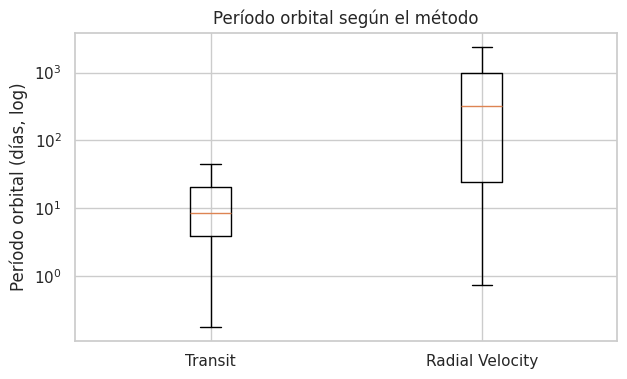

In [41]:
plt.figure(figsize=(7, 4))
plt.boxplot([transito, velocidad], showfliers=False)
plt.xticks([1, 2], ["Transit", "Radial Velocity"])
plt.yscale("log")
plt.title("Período orbital según el método")
plt.ylabel("Período orbital (días, log)")
plt.show()

Comparación de la mediana del período orbital de los dos métodos y gráfico de su distribución\. La mediana del tránsito es de 8,6 días y la de velocidad radial de 326 días, y las cajas casi no se superponen\.

La Hipótesis se cumple\.

### Hipótesis 2: los planetas cumplen la 3ª ley de Kepler

La 3ª ley de Kepler dice que el período al cuadrado es proporcional al semieje mayor al cubo \(P² ∝ a³\)\. En escala logarítmica eso es una recta con pendiente 1,5\.

In [42]:
kepler = limpio[["Orbit Semi-Major Axis", "Orbital Period Days"]].dropna()
log_a = np.log10(kepler["Orbit Semi-Major Axis"])
log_p = np.log10(kepler["Orbital Period Days"])

pendiente, ordenada = np.polyfit(log_a, log_p, 1)
print("Planetas usados:", len(kepler))
print("Pendiente:", round(pendiente, 2))

Planetas usados: 2605
Pendiente: 1.46


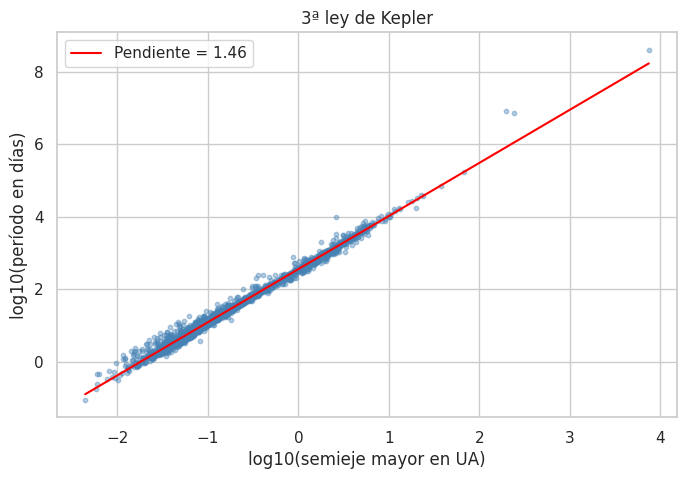

In [43]:
plt.figure(figsize=(8, 5))
plt.scatter(log_a, log_p, s=10, alpha=0.4, color="steelblue")
plt.plot(log_a.sort_values(), pendiente * log_a.sort_values() + ordenada, color="red",
         label=f"Pendiente = {pendiente:.2f}")
plt.title("3ª ley de Kepler")
plt.xlabel("log10(semieje mayor en UA)")
plt.ylabel("log10(período en días)")
plt.legend()
plt.show()

Ajuste de una recta entre el logaritmo del semieje mayor y el logaritmo del período\. La pendiente da 1,46, muy cerca del 1,5 teórico\. La pequeña dispersión se explica porque las estrellas tienen masas distintas\.

La Hipótesis se cumple\.

### Hipótesis 3: las estrellas con más metales tienen más planetas gigantes

Una estrella con más metales se forma en una nube con más material sólido, así que los planetas gigantes \(más de 100 masas terrestres\) deberían aparecer en estrellas con mayor metalicidad\.

In [44]:
metales = limpio.dropna(subset=["Mass", "Stellar Metallicity"])
gigantes = metales[metales["Mass"] > 100]["Stellar Metallicity"]
no_gigantes = metales[metales["Mass"] <= 100]["Stellar Metallicity"]

print("Mediana metalicidad con gigantes:", round(gigantes.median(), 3))
print("Mediana metalicidad sin gigantes:", round(no_gigantes.median(), 3))

Mediana metalicidad con gigantes: 0.09
Mediana metalicidad sin gigantes: 0.003


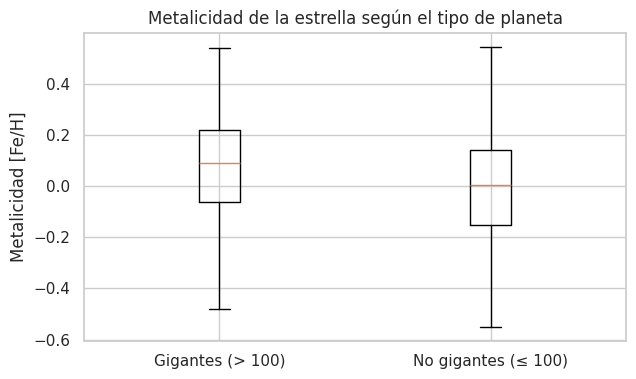

In [45]:
plt.figure(figsize=(7, 4))
plt.boxplot([gigantes, no_gigantes], showfliers=False)
plt.xticks([1, 2], ["Gigantes (> 100)", "No gigantes (≤ 100)"])
plt.title("Metalicidad de la estrella según el tipo de planeta")
plt.ylabel("Metalicidad [Fe/H]")
plt.show()

Separación de los planetas en gigantes y no gigantes y comparación de la metalicidad de sus estrellas\. La mediana es de 0,09 con gigantes y de 0,003 sin gigantes: las estrellas con gigantes tienen más metales\.

La Hipótesis se cumple\.

### Hipótesis 4: con los años se descubren planetas cada vez más chicos

Con instrumentos más precisos, la masa de los planetas descubiertos debería bajar con el tiempo\.

In [46]:
periodos = pd.cut(limpio["Discovery Year"], bins=[1988, 2005, 2010, 2015, 2021],
                  labels=["1989-2005", "2006-2010", "2011-2015", "2016-2021"])
masa_periodo = limpio.groupby(periodos, observed=True)["Mass"].median()
print(masa_periodo.round(0))

Discovery Year
1989-2005    532.0
2006-2010    387.0
2011-2015    178.0
2016-2021    130.0
Name: Mass, dtype: float64


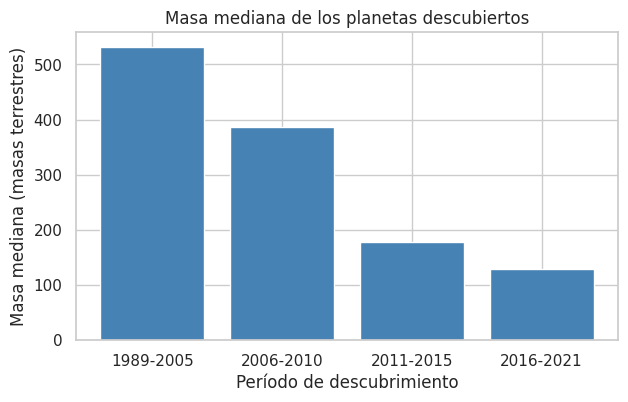

In [47]:
plt.figure(figsize=(7, 4))
plt.bar(masa_periodo.index.astype(str), masa_periodo.values, color="steelblue")
plt.title("Masa mediana de los planetas descubiertos")
plt.xlabel("Período de descubrimiento")
plt.ylabel("Masa mediana (masas terrestres)")
plt.show()

Agrupación de los descubrimientos en 4 períodos y cálculo de la masa mediana de cada uno\. Baja de 532 masas terrestres \(1989\-2005\) a 130 \(2016\-2021\)\. Parte de esta baja se debe a que el tránsito pasó a ser el método principal\.

La Hipótesis se cumple\.

# ✅ Conclusión del equipo

El catálogo de exoplanetas tiene dos grandes familias de planetas \(súper Tierras y gigantes\), y la ley de Kepler se cumple con los datos reales\. Pero el método de descubrimiento condiciona mucho lo que aparece en el catálogo: qué masas, qué órbitas y qué distancias\. Las 4 hipótesis se cumplen\. Para la próxima entrega, las relaciones entre las variables de la estrella y del planeta abren la puerta a modelos para predecir la masa o clasificar el método de descubrimiento\.

# TERCERA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Introducción y descripción del dataset
Planteamiento del objetivo del proyecto
Planteamiento de hipótesis y resumen de las conclusiones sobre las hipótesis
Análisis EDA
Análisis univariado
Análisis Bivariado y/o multivariado
Graficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.
Aplicación de modelos de Regresión,
Clasificación o Agrupación según lo planteado en el objetivo\.
\(mínimo 3 modelos\)
Métricas de evaluación del modelo aplicado
Selección del modelo más indicado en base a las métricas\.

## 🔍 Introducción

En esta entrega final usamos el catálogo de exoplanetas para entrenar modelos que **estimen la masa de un planeta** a partir de su órbita y de los datos de su estrella. Partimos del dataset limpio de la segunda entrega (`limpio`), revisamos si alcanzan los datos, entrenamos tres modelos de regresión y elegimos el mejor según su error.

## Objetivo del proyecto

En la primera entrega propusimos tres usos posibles del dataset. Los comparamos para elegir uno solo:

| Alternativa | Problema | Decisión |
|---|---|---|
| Clasificar el método de descubrimiento | El método ya está en la base y variables como el período dependen de él: la predicción sería circular. | Descartada |
| Agrupar planetas (clustering) | Los grupos que se ven en el EDA son en buena parte sesgo de detección y no hay un criterio claro para elegir el mejor modelo. | Descartada |
| **Predecir la masa del planeta (regresión)** | La masa falta en el 56 % de los planetas, pero quedan más de 1300 registros completos (ver sección 1). | **Elegida** |

**Objetivo:** estimar la masa de un planeta a partir de su período orbital, la cantidad de planetas de su sistema y las características de su estrella.

## Resumen de las hipótesis

| Hipótesis (segunda entrega) | Resultado |
|---|---|
| 1. Los planetas de tránsito tienen órbitas más cortas que los de velocidad radial | Se cumple: mediana de 8,6 días contra 326 |
| 2. Los planetas cumplen la 3ª ley de Kepler | Se cumple: pendiente de 1,46, cerca del 1,5 teórico |
| 3. Las estrellas con más metales tienen más planetas gigantes | Se cumple: metalicidad mediana de 0,09 contra 0,003 |
| 4. Con los años se descubren planetas cada vez más chicos | Se cumple: la masa mediana baja de 532 a 130 masas terrestres |

Aclaración: las hipótesis 3 y 4 están influidas por el método de descubrimiento (la mayoría de los gigantes se descubrió por velocidad radial y el tránsito, que encuentra planetas más chicos, dominó en los últimos años).

# 📁 Dataset elegido – Exoplanetas 2021 (all_exoplanets_2021.csv)

## 📝 Descripción del Dataset

Catálogo de 4575 exoplanetas confirmados hasta 2021, basado en el NASA Exoplanet Archive. Cada fila es un planeta, con su método y año de descubrimiento, sus datos orbitales, su masa y los datos de su estrella.

Unidades de las variables que se usan en esta entrega:
- **Mass** (variable a predecir): masas terrestres.
- **Orbital Period Days**: días.
- **Num Planets**: cantidad de planetas del sistema.
- **Stellar Mass** y **Stellar Radius**: masas y radios solares.
- **Stellar Effective Temperature**: Kelvin.
- **Stellar Metallicity**: [Fe/H], proporción de metales respecto del Sol en escala logarítmica.

## Importación de Librerías

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")

## 1\. Carga y exploración de datos

### ¿Los nulos de la masa siguen un patrón?

Porcentaje de planetas sin masa según el método de descubrimiento, para ver si los datos faltan al azar o no.

In [49]:
nulos_metodo = limpio.groupby("Discovery Method")["Mass"].agg(planetas="size", con_masa="count")
nulos_metodo["% sin masa"] = (100 * (1 - nulos_metodo["con_masa"] / nulos_metodo["planetas"])).round(1)
nulos_metodo.sort_values("planetas", ascending=False)

,planetas,con_masa,% sin masa
Discovery Method,,,
Transit,3444,886,74.3
Radial Velocity,899,899,0.0
Microlensing,120,120,0.0
Imaging,54,50,7.4
Transit Timing Variations,22,18,18.2
Eclipse Timing Variations,16,16,0.0
Orbital Brightness Modulation,9,6,33.3
Pulsar Timing,7,7,0.0
Pulsation Timing Variations,2,2,0.0


📌 Los nulos no son al azar: el 74,3% de los planetas descubiertos por tránsito no tiene masa, mientras que en velocidad radial y microlente la masa está siempre. El tránsito mide el radio, no la masa, así que solo se conoce la masa de los tránsitos que tuvieron una medición adicional. Por eso no se imputa la masa: se trabaja solo con los planetas que la tienen, sabiendo que los tránsitos quedan subrepresentados.

### ¿Cuántos registros quedan para predecir la masa?

Conteo de los planetas con masa conocida y con todas las variables del modelo. Se usa el período y no el semieje mayor, porque están casi perfectamente correlacionados (0,99) y el semieje tiene muchos más nulos. No se usan el año de descubrimiento ni la distancia, porque dependen de cómo se detectó el planeta y no del planeta en sí.

In [50]:
variables = ["Orbital Period Days", "Num Planets", "Stellar Mass", "Stellar Radius",
             "Stellar Effective Temperature", "Stellar Metallicity"]
con_masa = limpio.dropna(subset=["Mass"])
completos = con_masa.dropna(subset=variables)

print("Planetas con masa:", len(con_masa))
print("Planetas con masa y todas las variables:", len(completos))
print("\nNulos de cada variable entre los planetas con masa:")
print(con_masa[variables].isna().sum().sort_values(ascending=False))
print("\nMétodo de descubrimiento (%): con masa vs. completos")
print(pd.concat([con_masa["Discovery Method"].value_counts(normalize=True),
                 completos["Discovery Method"].value_counts(normalize=True)],
                axis=1, keys=["con masa", "completos"]).fillna(0).mul(100).round(1))

Planetas con masa: 2006
Planetas con masa y todas las variables: 1325

Nulos de cada variable entre los planetas con masa:
Stellar Metallicity              524
Stellar Radius                   423
Stellar Effective Temperature    318
Orbital Period Days              156
Stellar Mass                      30
Num Planets                        0
dtype: int64

Método de descubrimiento (%): con masa vs. completos
                               con masa  completos
Discovery Method                                  
Radial Velocity                    44.8       42.8
Transit                            44.2       56.5
Microlensing                        6.0        0.0
Imaging                             2.5        0.1
Transit Timing Variations           0.9        0.4
Eclipse Timing Variations           0.8        0.0
Pulsar Timing                       0.3        0.0
Orbital Brightness Modulation       0.3        0.3
Pulsation Timing Variations         0.1        0.0
Disk Kinematics            

📌 De 2006 planetas con masa, quedan 1325 con todas las variables, una cantidad suficiente para entrenar y comparar modelos de regresión. La metalicidad y el radio de la estrella son las variables que más filas descartan. Al exigir datos completos desaparecen los planetas de microlente y casi todos los de imagen directa: el 99 % de los que quedan son de tránsito (56,5 %) o de velocidad radial (42,8 %). Por eso el modelo solo vale para planetas de esos dos métodos.

## 2\. Visualizaciones y análisis

### Distribución de la masa a predecir

Histograma del logaritmo de la masa de los planetas que se usan en el modelo, y rango de la masa.

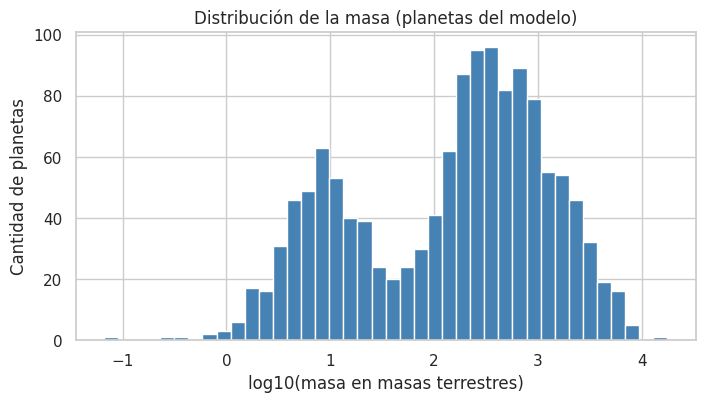

Masa mínima: 0.066
Masa máxima: 17668.1697


In [51]:
plt.figure(figsize=(8, 4))
plt.hist(np.log10(completos["Mass"]), bins=40, color="steelblue", edgecolor="white")
plt.title("Distribución de la masa (planetas del modelo)")
plt.xlabel("log10(masa en masas terrestres)")
plt.ylabel("Cantidad de planetas")
plt.show()

print("Masa mínima:", completos["Mass"].min())
print("Masa máxima:", completos["Mass"].max())

📌 La masa va de 0,07 a más de 17.000 masas terrestres, y en escala logarítmica se ven las dos familias de planetas de la segunda entrega (súper Tierras y gigantes). Por eso los modelos predicen el **logaritmo de la masa**: si se usara la masa directa, el error de los pocos planetas gigantes dominaría la métrica.

### ¿Qué variables se relacionan con la masa?

Correlación de Spearman (la misma que en la segunda entrega) entre cada variable del modelo y la masa del planeta.

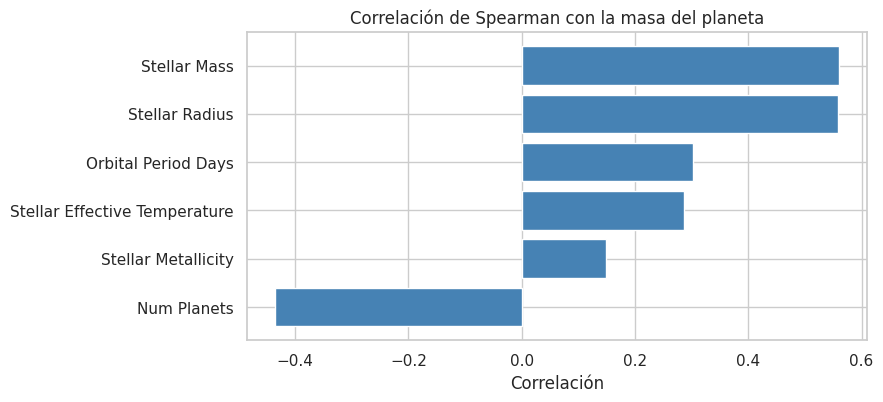

Num Planets                     -0.44
Stellar Metallicity              0.15
Stellar Effective Temperature    0.29
Orbital Period Days              0.30
Stellar Radius                   0.56
Stellar Mass                     0.56
Name: Mass, dtype: float64


In [52]:
correlacion_masa = completos[variables + ["Mass"]].corr(method="spearman")["Mass"].drop("Mass").sort_values()

plt.figure(figsize=(8, 4))
plt.barh(correlacion_masa.index, correlacion_masa.values, color="steelblue")
plt.title("Correlación de Spearman con la masa del planeta")
plt.xlabel("Correlación")
plt.show()

print(correlacion_masa.round(2))

📌 La masa y el radio de la estrella son las variables más relacionadas con la masa del planeta (0,56). La cantidad de planetas del sistema tiene una relación negativa (-0,44): los sistemas con muchos planetas suelen tener planetas chicos. El período y la temperatura tienen una relación más débil (0,30 y 0,29) y la metalicidad, la más baja (0,15).

Quedan 1325 planetas completos, casi todos de tránsito y velocidad radial. Ninguna variable alcanza sola para predecir la masa, así que hay que combinarlas en un modelo, y conviene predecir la masa en escala logarítmica.

## 3\. Modelos de Regresión

### División en entrenamiento y prueba

Se arman las variables de entrada (X) y la variable a predecir (y = log10 de la masa). El período también se pasa a logaritmo, porque va de menos de un día a miles de días. Se separa el 80 % para entrenar y el 20 % para probar, y se escalan las variables con `StandardScaler`.

In [53]:
X = completos[variables].copy()
X["Orbital Period Days"] = np.log10(X["Orbital Period Days"])
y = np.log10(completos["Mass"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (1060, 6)
Prueba: (265, 6)


📌 Quedan 1060 planetas para entrenar y 265 para probar. Los tres modelos se evalúan con el **error cuadrático medio (MSE)** sobre el conjunto de prueba: cuanto más bajo, mejor.

### Modelo 1: Regresión lineal

Supone que el logaritmo de la masa es una combinación lineal de las variables.

In [54]:
lineal = LinearRegression()
lineal.fit(X_train_scaled, y_train)
pred_lineal = lineal.predict(X_test_scaled)

mse_lineal = mean_squared_error(y_test, pred_lineal)
print("MSE regresión lineal:", round(mse_lineal, 3))

MSE regresión lineal: 0.35


📌 La regresión lineal obtiene un MSE de 0,350. Solo capta relaciones en línea recta, y la masa tiene dos familias de planetas bien separadas.

### Modelo 2: Árbol de decisión

Divide a los planetas con preguntas del tipo "¿el período es mayor a X días?" y predice el promedio de cada grupo.

In [55]:
arbol = DecisionTreeRegressor(random_state=42)
arbol.fit(X_train_scaled, y_train)
pred_arbol = arbol.predict(X_test_scaled)

mse_arbol = mean_squared_error(y_test, pred_arbol)
print("MSE árbol de decisión:", round(mse_arbol, 3))

MSE árbol de decisión: 0.49


📌 El árbol obtiene un MSE de 0,490, el peor de los tres. Un solo árbol sin límite de profundidad tiende a ajustarse demasiado a los datos de entrenamiento (sobreajuste) y a generalizar peor.

### Modelo 3: Random Forest

Entrena muchos árboles, cada uno con una muestra distinta de los datos, y promedia sus predicciones.

In [56]:
bosque = RandomForestRegressor(random_state=42)
bosque.fit(X_train_scaled, y_train)
pred_bosque = bosque.predict(X_test_scaled)

mse_bosque = mean_squared_error(y_test, pred_bosque)
print("MSE Random Forest:", round(mse_bosque, 3))

MSE Random Forest: 0.27


📌 Random Forest obtiene un MSE de 0,271, el más bajo. Al promediar muchos árboles reduce el sobreajuste de un árbol solo.

## 4\. Selección del modelo

### Comparación de los tres modelos

Tabla con el MSE de cada modelo sobre el mismo conjunto de prueba, ordenada de menor a mayor.

In [57]:
comparacion = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Árbol de decisión", "Random Forest"],
    "MSE": [mse_lineal, mse_arbol, mse_bosque],
}).sort_values("MSE").round(3)
comparacion

,Modelo,MSE
2,Random Forest,0.27
0,Regresión lineal,0.35
1,Árbol de decisión,0.49


📌 **Modelo seleccionado: Random Forest**, con el menor MSE (0,271), seguido por la regresión lineal (0,350) y el árbol de decisión (0,490).

# ✅ Conclusión del equipo

El objetivo era estimar la masa de un exoplaneta a partir de su órbita y de su estrella. Aunque la masa falta en el 56 % del catálogo, quedaron 1325 planetas completos, suficientes para entrenar y comparar tres modelos de regresión. **Random Forest fue el mejor modelo**, con el menor error cuadrático medio.

Limitaciones a tener en cuenta:
- La masa no se imputó, porque sus nulos no son al azar (faltan sobre todo en los planetas de tránsito). Se trabajó solo con los planetas que la tienen.
- El modelo solo vale para planetas de tránsito y velocidad radial con datos completos de su estrella.
- El catálogo no incluye el radio del planeta, que sería la variable más útil para estimar su masa.

## 🔗 Repositorios de GitHub

- Jorge A. Mendoza: https://github.com/jorgearnaldo01/DSIA_Mendoza_Jorge_A
- Constanza Soler: https://github.com/Constanza1976/DSIA_Soler_Constanza
- Catalina Frione: https://github.com/Catafrione/DSIA_Frione_Catalina
- Franco Alfredo Díaz: https://github.com/31013998/DSIA_Diaz_Franco
- Federico Suárez: https://github.com/fedetrus/DSIA_Suarez_Federico

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=d7eb8a35-975d-44f1-bd2c-9ca3e5f24fb8' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>